# IVG-UAV — Ripe/unripe fruit detection with the committed fine-tuned YOLOv8n

**Paper:** *IVG-UAV: An Intelligent Voice-Guided UAV System for Autonomous Ripe Fruit Harvesting with Vision-Based Classification and Adaptive Path Planning* — arXiv:2610.09398v1 · RG DOI 10.13140/rg.2.2.24215.53923

**Author code (pinned):** [https://github.com/dinhtrung1308/IVG-UAV/tree/4d42dbbf5748a1ce8afdbf3b7c9df3477a12772f](https://github.com/dinhtrung1308/IVG-UAV/tree/4d42dbbf5748a1ce8afdbf3b7c9df3477a12772f) @ commit `4d42dbbf5748a1ce8afdbf3b7c9df3477a12772f`

## Scope (what this notebook does / does not do)

This notebook reproduces the paper's **detection module** (§III-B3) as a minimal, faithful inference demo, following the author's own `planning_detection/detection.py`:

- Load the **committed fine-tuned checkpoint** `planning_detection/runs/detect/train-2/weights/best.pt` (YOLOv8n, trained by the authors with `args.yaml`: `imgsz=640`, `device: cpu`, classes `0: ripe_apple`, `1: unripe_apple` from `data.yaml`).
- Run inference with the author's confidence threshold **`conf=0.25`** on the **author's committed validation images** (`planning_detection/dataset/images/val/img17–img20`) and on the author's own sample `planning_detection/test-gazebo.png`.
- Compare predictions with the **reference YOLO annotations** committed next to the images.

**Out of scope:** voice command (Whisper), LLM task planning (Gemini 2.5 Flash / Phi-3), Gazebo + PX4 SITL navigation and RRT* path planning, and video tracking. These need ROS 2 / simulation infrastructure and API keys and are not part of this minimal demo. A one-image result does **not** reproduce the paper's dataset-level metrics (e.g. TABLE I average ripe fruit detection rate 63.1% in simulation).

**Execution status: validated** — this notebook was executed end-to-end on a fresh Google Colab **CPU** runtime (see the Interpretation cell for the validation date).

## 概要（日本語）

このノートブックは、arXiv:2610.09398v1「IVG-UAV」の**検出モジュール**を最小構成で再現します。著者自身のリポジトリ（commit `4d42dbbf5748a1ce8afdbf3b7c9df3477a12772f`）に含まれる学習済みチェックポイント `best.pt`（YOLOv8n）を、著者の推論コード `detection.py` と同じ設定（`conf=0.25`）で、コミット済みの検証用画像4枚とGazebo標本画像に実行し、コミット済みの正解アノテーション（YOLO形式）と比較します。音声認識・LLMタスク計画・Gazebo/PX4航法・トラッキングは範囲外です。実行は無料のCPUランタイムで数分です。

⚠️ Note: the repository has **no LICENSE file**, and the paper text does not cite the companion repository (attribution rests on the exact title match in the repo README). Reuse terms are therefore uncertain; this notebook is for study purposes.

## Runtime selection — CPU (recommended)

Select **Runtime → Change runtime type → CPU** in Colab. The authors trained this checkpoint on CPU (`args.yaml`: `device: cpu`), and YOLOv8n inference on small orchard images is fast on CPU, so a GPU runtime is unnecessary for this demo. The notebook also detects and reports any GPU if one is attached, but the CPU path is the validated one.

**Run all:** Runtime → Run all. Expected total time ≈ 3–6 minutes, ≈ 6.4 MB of downloads (mostly the 6.3 MB checkpoint).

**実行環境（日本語）:** 上部メニューの「ランタイム → ランタイムのタイプを変更」で **CPU** を選択してください。著者もCPUで学習しており、YOLOv8nの推論はCPUで十分速いためGPUは不要です。すべてのセルを実行（ランタイム → すべてのセルを実行）すると約3〜6分、ダウンロードは約6.4 MBです。

In [ ]:
import sys, platform
print("Python:", sys.version.split()[0], "|", platform.platform())
try:
    import torch
    print("torch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())
except ImportError:
    print("torch not yet installed")
import PIL, cv2  # OpenCV ships with Colab images
print("Pillow:", PIL.__version__, "| OpenCV:", cv2.__version__)

Python: 3.13.18 | Linux-6.6.159+-x86_64-with-glibc2.39


torch: 2.14.1+cpu | CUDA available: False
Pillow: 11.3.0 | OpenCV: 5.0.0


## 1. Install the ultralytics package

The author code imports `ultralytics.YOLO` (`detection.py`, `tracker.py`). We install the current `ultralytics` release; the exact installed version is printed for reproducibility. Pillow/OpenCV needed for drawing come preinstalled on Colab.

**説明（日本語）:** 著者コードと同じ `ultralytics` パッケージをインストールし、バージョンを記録します。

In [ ]:
%pip install -q --progress-bar off ultralytics
import ultralytics, torch
print("ultralytics:", ultralytics.__version__, "| torch:", torch.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


ultralytics: 8.4.220 | torch: 2.14.1+cpu


## 2. Download the pinned author files (checkpoint, validation images, reference labels)

All files come from the author repository at the **pinned commit** `4d42dbbf5748a1ce8afdbf3b7c9df3477a12772f` via `raw.githubusercontent.com`, so the bytes are exactly what the authors committed. Before use, each file is verified against its **Git blob SHA-1** and byte size taken from the GitHub tree of that commit. Files: `best.pt` (fine-tuned weights), 4 validation images + their YOLO label files, `data.yaml`, and the author's Gazebo sample image.

**説明（日本語）:** 著者リポジトリの固定コミットから、チェックポイント `best.pt`、検証用画像4枚とその正解ラベル、`data.yaml`、Gazebo標本画像をダウンロードし、GitブロブSHA-1とバイト数で完全性を検証します。

In [ ]:
import hashlib, urllib.request
from pathlib import Path

COMMIT = "4d42dbbf5748a1ce8afdbf3b7c9df3477a12772f"
RAW = "https://raw.githubusercontent.com/dinhtrung1308/IVG-UAV/4d42dbbf5748a1ce8afdbf3b7c9df3477a12772f"
BASE = Path("/content/ivg_uav"); BASE.mkdir(exist_ok=True)

# (repo path, expected git blob sha1, expected size)  -- from the GitHub tree at the pinned commit
FILES = [
    ("planning_detection/runs/detect/train-2/weights/best.pt", "5a9bd3e039b33157bfe64798d5edfe3a0cddf562", 6256106),
    ("planning_detection/dataset/images/val/img17.png", "3b1a2bf60e774298bb85788d36b7aba1df0b576e", 56979),
    ("planning_detection/dataset/images/val/img18.jpg", "8fabc647d805d13f960ce3e1808945de3ce90241", 2428),
    ("planning_detection/dataset/images/val/img19.png", "064837dbd376d4eaec858f1dfde605d0e94c741b", 61498),
    ("planning_detection/dataset/images/val/img20.png", "fbf316d44f128604ecd1f137f1b1082ac88dadfb", 719535),
    ("planning_detection/dataset/labels/val/img17.txt", "390450da24571bbd918380fe845969c9bdb4a46c", 38),
    ("planning_detection/dataset/labels/val/img18.txt", "fab15b1684bb708c52f5c8b28a86b60ba12b2f3d", 38),
    ("planning_detection/dataset/labels/val/img19.txt", "731c5d9ffd732e1579b0526de03aee2492dda0cc", 38),
    ("planning_detection/dataset/labels/val/img20.txt", "cf7b57229375439f12915b6d3cef3d767491637f", 38),
    ("planning_detection/data.yaml", "d01461fb2058f5fcf7f3bc5a0f7486a647d36c98", 91),
    ("planning_detection/test-gazebo.png", "16c1ca26cb8aa38aa49d428e69abf1fbce6db286", 29612),
]

def git_blob_sha(data: bytes) -> str:
    return hashlib.sha1(b"blob %d\x00" % len(data) + data).hexdigest()

for rel, sha, size in FILES:
    dest = BASE / rel
    dest.parent.mkdir(parents=True, exist_ok=True)
    if not dest.exists() or dest.stat().st_size != size:
        urllib.request.urlretrieve(f"{RAW}/{rel}", dest)
    data = dest.read_bytes()
    assert len(data) == size, f"{rel}: size {len(data)} != expected {size}"
    got = git_blob_sha(data)
    assert got == sha, f"{rel}: git blob sha {got} != expected {sha}"
    print(f"OK  {len(data):>9,} B  {got[:12]}  {rel}")
print("\nAll pinned files verified against the GitHub tree of commit", COMMIT[:12])

OK  6,256,106 B  5a9bd3e039b3  planning_detection/runs/detect/train-2/weights/best.pt
OK     56,979 B  3b1a2bf60e77  planning_detection/dataset/images/val/img17.png
OK      2,428 B  8fabc647d805  planning_detection/dataset/images/val/img18.jpg


OK     61,498 B  064837dbd376  planning_detection/dataset/images/val/img19.png
OK    719,535 B  fbf316d44f12  planning_detection/dataset/images/val/img20.png


OK         38 B  390450da2457  planning_detection/dataset/labels/val/img17.txt
OK         38 B  fab15b1684bb  planning_detection/dataset/labels/val/img18.txt
OK         38 B  731c5d9ffd73  planning_detection/dataset/labels/val/img19.txt


OK         38 B  cf7b57229375  planning_detection/dataset/labels/val/img20.txt
OK         91 B  d01461fb2058  planning_detection/data.yaml
OK     29,612 B  16c1ca26cb8a  planning_detection/test-gazebo.png

All pinned files verified against the GitHub tree of commit 4d42dbbf5748


## 3. Class names from the author's `data.yaml`

The committed `data.yaml` defines the two detector classes (`0: ripe_apple`, `1: unripe_apple`). We parse it rather than hard-coding the mapping.

**説明（日本語）:** 著者の `data.yaml` からクラス名（0: ripe_apple, 1: unripe_apple）を読み込みます。

In [ ]:
import yaml
cfg = yaml.safe_load((BASE / "planning_detection/data.yaml").read_text())
class_names = {int(k): v for k, v in cfg["names"].items()}
print("data.yaml:", cfg)
print("class_names:", class_names)
assert class_names == {0: "ripe_apple", 1: "unripe_apple"}

data.yaml: {'path': 'dataset', 'train': 'images/train', 'val': 'images/val', 'names': {0: 'ripe_apple', 1: 'unripe_apple'}}
class_names: {0: 'ripe_apple', 1: 'unripe_apple'}


## 4. Preview the validation inputs with their reference annotations

Each 38-byte label file holds YOLO-format boxes (`class cx cy w h`, normalized). We decode them and draw the **reference annotations** (green boxes) on the four committed validation images. This is the ground truth committed by the authors — not a model output.

**説明（日本語）:** 著者がコミットした正解アノテーション（YOLO形式、緑枠）を検証用画像4枚に重ねて表示します。モデル出力ではありません。

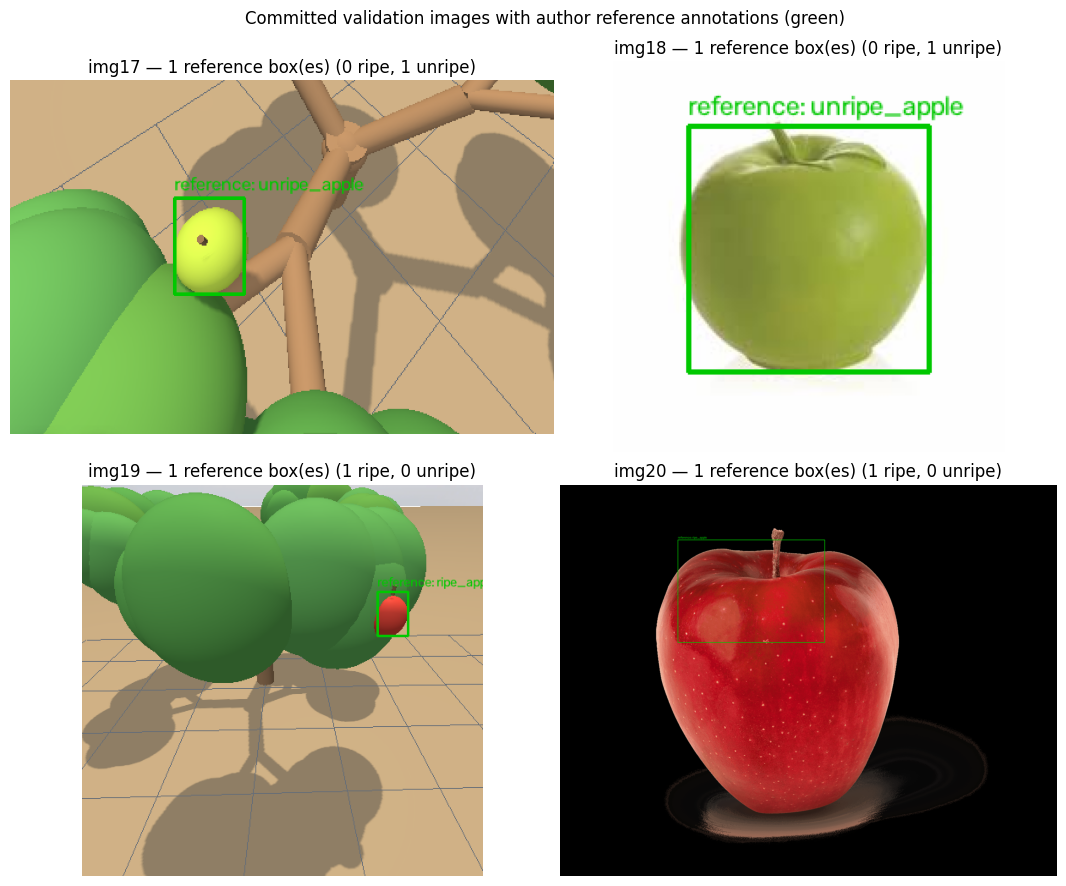

In [ ]:
import cv2, numpy as np
import matplotlib.pyplot as plt

def load_yolo_labels(txt_path, img_w, img_h):
    boxes = []
    for line in txt_path.read_text().strip().splitlines():
        c, cx, cy, w, h = line.split()
        cx, cy, w, h = float(cx)*img_w, float(cy)*img_h, float(w)*img_w, float(h)*img_h
        boxes.append((int(c), cx-w/2, cy-h/2, cx+w/2, cy+h/2))
    return boxes

def draw_boxes(img, boxes, names, color, label_prefix):
    out = img.copy()
    for c, x1, y1, x2, y2 in boxes:
        p1, p2 = (int(x1), int(y1)), (int(x2), int(y2))
        cv2.rectangle(out, p1, p2, color, 2)
        cv2.putText(out, f"{label_prefix}: {names[c]}", (p1[0], max(p1[1]-6, 12)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1, cv2.LINE_AA)
    return out

VAL_STEMS = ["img17", "img18", "img19", "img20"]
val_images, ref_boxes = {}, {}
for stem in VAL_STEMS:
    img_path = next((BASE/"planning_detection/dataset/images/val").glob(stem + ".*"))
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    val_images[stem] = img
    ref_boxes[stem] = load_yolo_labels(BASE/f"planning_detection/dataset/labels/val/{stem}.txt", img.shape[1], img.shape[0])

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, stem in zip(axes.flat, VAL_STEMS):
    ax.imshow(draw_boxes(val_images[stem], ref_boxes[stem], class_names, (0, 200, 0), "reference"))
    n_ripe = sum(1 for b in ref_boxes[stem] if b[0] == 0)
    ax.set_title(f"{stem} — {len(ref_boxes[stem])} reference box(es) ({n_ripe} ripe, {len(ref_boxes[stem])-n_ripe} unripe)")
    ax.axis("off")
plt.suptitle("Committed validation images with author reference annotations (green)")
plt.tight_layout(); plt.show()

## 5. Load the committed fine-tuned checkpoint

This mirrors `detection.py` line-by-line: `YOLO(".../train-2/weights/best.pt")`. We assert the class-name mapping stored inside the checkpoint matches the author's `data.yaml` (2 classes, `imgsz=640` training).

**説明（日本語）:** `detection.py` と同じ方法でコミット済みの `best.pt` を読み込み、チェックポイント内のクラス名が `data.yaml` と一致することを確認します。

In [ ]:
from ultralytics import YOLO

WEIGHTS = BASE / "planning_detection/runs/detect/train-2/weights/best.pt"
model = YOLO(str(WEIGHTS))          # exactly as in author detection.py
ckpt_names = {int(k): v for k, v in model.names.items()}
print("checkpoint task:", model.task, "| classes:", ckpt_names)
assert ckpt_names == class_names, "checkpoint class mapping differs from data.yaml"
print("Model loaded from", WEIGHTS.name)

checkpoint task: detect | classes: {0: 'ripe_apple', 1: 'unripe_apple'}
Model loaded from best.pt


## 6. Run the author-style inference on the validation images (`conf=0.25`)

`detection.py` calls `model(..., conf=0.25, save=True)` and prints `label conf [x1, y1, x2, y2]` per box. We do the same on each validation image (inference device: CPU), then draw the **model predictions** (orange boxes) side-by-side with the reference annotations for visual comparison.

**説明（日本語）:** `detection.py` と同じ `conf=0.25` で検証用画像に推論を実行し、モデル予測（オレンジ枠）を正解アノテーション（緑枠）と並べて表示します。

In [ ]:
CONF = 0.25   # author detection.py threshold
predictions = {}
for stem in VAL_STEMS:
    results = model.predict(val_images[stem], conf=CONF, verbose=False)
    r = results[0]
    preds = [(int(b.cls[0]), float(b.conf[0]), [round(v, 1) for v in b.xyxy[0].tolist()])
             for b in r.boxes]
    predictions[stem] = preds
    print(f"{stem}: {len(preds)} prediction(s)")
    for c, conf, xyxy in preds:
        print(f"   {class_names[c]}  conf={conf:.2f}  xyxy={xyxy}")

img17: 2 prediction(s)
   ripe_apple  conf=0.38  xyxy=[0.0, 72.6, 133.6, 293.2]
   unripe_apple  conf=0.31  xyxy=[135.5, 101.6, 198.6, 181.0]
img18: 1 prediction(s)
   ripe_apple  conf=0.97  xyxy=[33.8, 13.2, 189.3, 180.0]


img19: 2 prediction(s)
   ripe_apple  conf=0.84  xyxy=[344.0, 121.2, 385.5, 183.9]
   ripe_apple  conf=0.27  xyxy=[6.6, 0.0, 383.8, 233.4]
img20: 1 prediction(s)
   ripe_apple  conf=0.83  xyxy=[6.4, 152.7, 1643.1, 1692.1]


### Visual comparison: reference annotations vs. model predictions

We render each validation image twice: the author's committed reference annotations in green, and the model's predicted boxes in orange, using the same drawing helper. This side-by-side view makes false positives/negatives on these four examples directly visible; the helper also computes IoU for the summary table below.

**説明（日本語）:** 正解アノテーション（緑）とモデル予測（オレンジ）を並べて描画し、目視比較できるようにします。このヘルパーの IoU 関数は次の集計表でも使います。

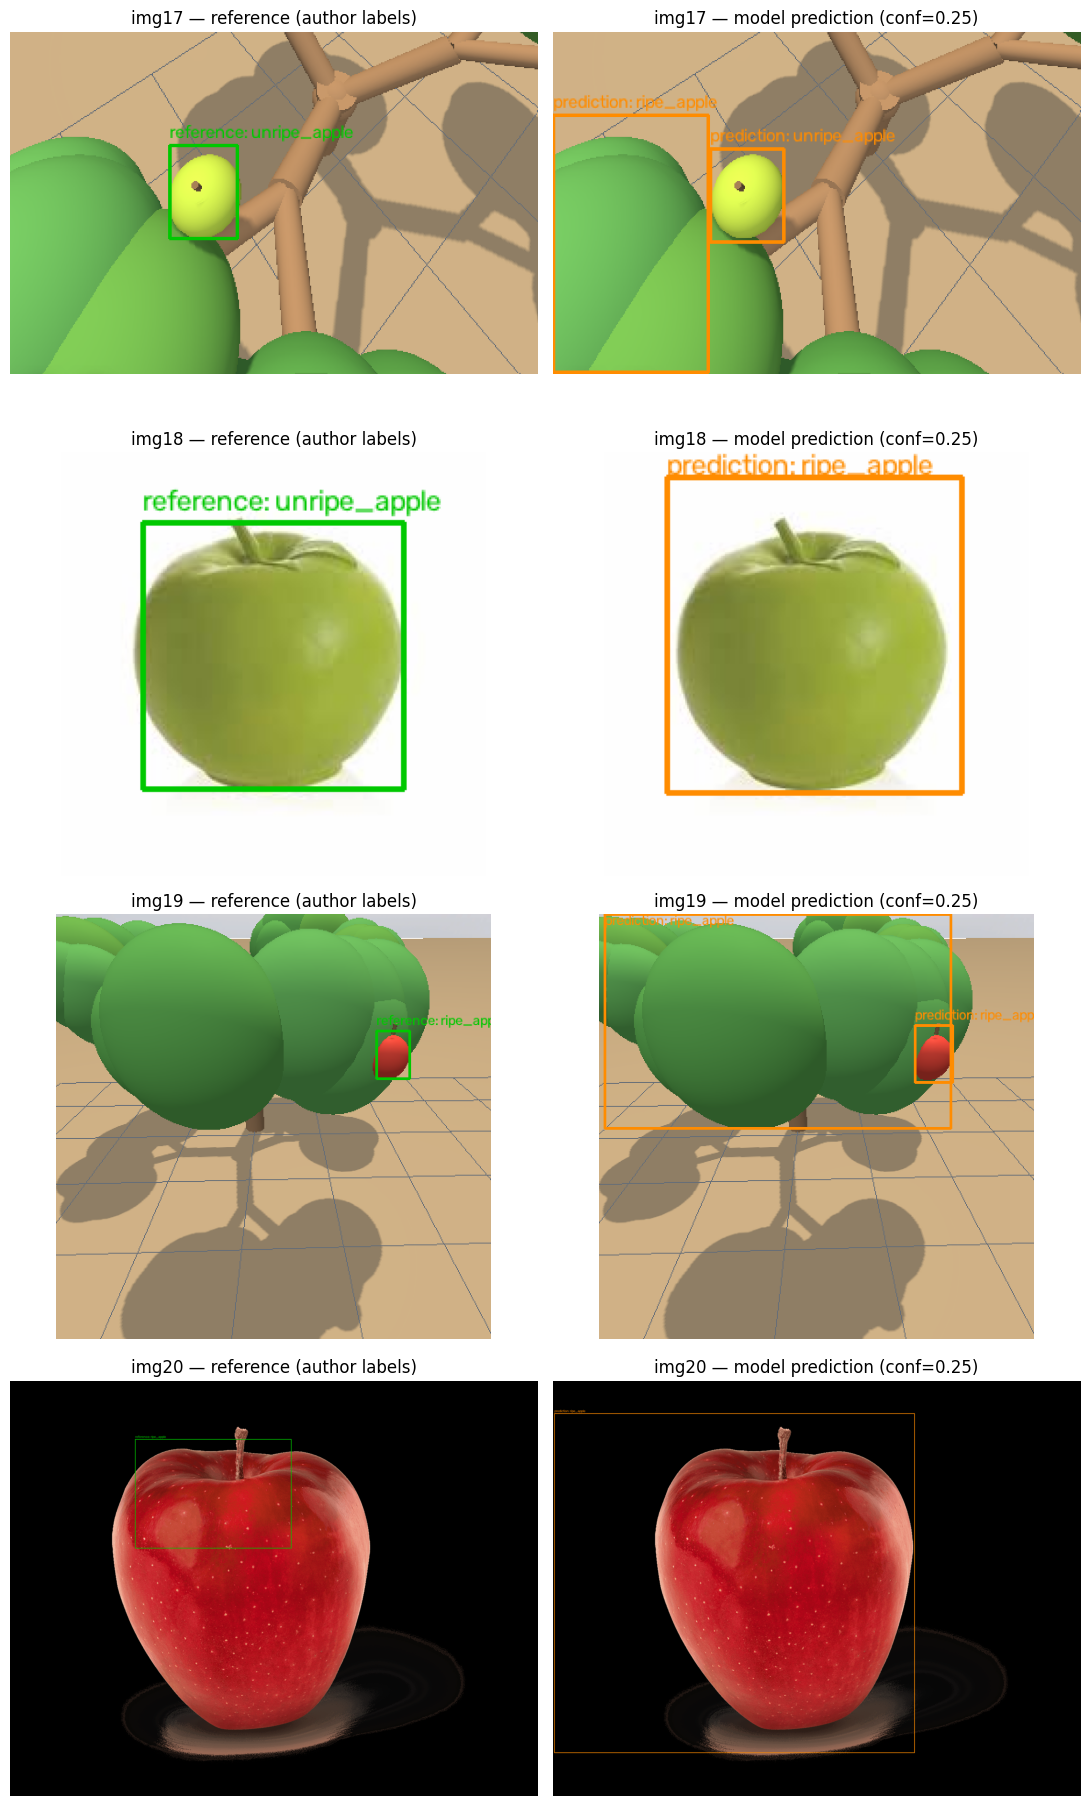

Saved /content/ivg_uav/ref_vs_pred.png


In [ ]:
def iou(a, b):
    ax1, ay1, ax2, ay2 = a[1:]; bx1, by1, bx2, by2 = b[1:]
    ix1, iy1, ix2, iy2 = max(ax1,bx1), max(ay1,by1), min(ax2,bx2), min(ay2,by2)
    inter = max(0, ix2-ix1) * max(0, iy2-iy1)
    ua = (ax2-ax1)*(ay2-ay1) + (bx2-bx1)*(by2-by1) - inter
    return inter/ua if ua > 0 else 0.0

fig, axes = plt.subplots(len(VAL_STEMS), 2, figsize=(11, 4.6*len(VAL_STEMS)))
for row, stem in enumerate(VAL_STEMS):
    ref_img = draw_boxes(val_images[stem], ref_boxes[stem], class_names, (0, 200, 0), "reference")
    pred_boxes = [(c, *xyxy) for c, conf, xyxy in predictions[stem]]
    pred_img = draw_boxes(val_images[stem], pred_boxes, class_names, (255, 140, 0), "prediction")
    axes[row, 0].imshow(ref_img); axes[row, 0].set_title(f"{stem} — reference (author labels)")
    axes[row, 1].imshow(pred_img); axes[row, 1].set_title(f"{stem} — model prediction (conf=0.25)")
    for ax in axes[row]: ax.axis("off")
plt.tight_layout(); plt.savefig("/content/ivg_uav/ref_vs_pred.png", dpi=110, bbox_inches="tight")
plt.show()
print("Saved /content/ivg_uav/ref_vs_pred.png")

## 7. Reference vs. prediction — small comparison table

Per image: reference boxes, predicted boxes, and reference boxes matched by a prediction at IoU ≥ 0.5 (a rough, single-example check — **not** the paper's dataset-level evaluation, and `img17–img20` are only 4 of the validation split). A CSV export is written next to the plots.

**説明（日本語）:** 画像ごとに正解ボックス数・予測ボックス数・IoU≥0.5で対応付けできた正解数を表にまとめ、CSVにも保存します。4枚のみの参考値であり、論文のデータセット全体の評価ではありません。

In [ ]:
import pandas as pd

rows = []
for stem in VAL_STEMS:
    n_ref = len(ref_boxes[stem])
    n_pred = len(predictions[stem])
    stem_pred_boxes = [(c, *xyxy) for c, _, xyxy in predictions[stem]]
    matched = 0
    for rb in ref_boxes[stem]:
        if any(iou(rb, pb) >= 0.5 for pb in stem_pred_boxes):
            matched += 1
    rows.append({"image": stem,
                 "reference_boxes": n_ref,
                 "predicted_boxes": n_pred,
                 "ref_matched_iou>=0.5": matched})
    per_class = {class_names[c]: sum(1 for b in ref_boxes[stem] if b[0] == c) for c in class_names}
    rows[-1].update({f"ref_{k}": v for k, v in per_class.items()})

df = pd.DataFrame(rows)
display(df)
df.to_csv("/content/ivg_uav/ref_vs_pred_summary.csv", index=False)
print("Saved /content/ivg_uav/ref_vs_pred_summary.csv")

,image,reference_boxes,predicted_boxes,ref_matched_iou>=0.5,ref_ripe_apple,ref_unripe_apple
0,img17,1,2,1,0,1
1,img18,1,1,1,0,1
2,img19,1,2,1,1,0
3,img20,1,1,0,1,0


Saved /content/ivg_uav/ref_vs_pred_summary.csv


## 8. The author's own sample: `test-gazebo.png` (echo of `detection.py`)

Finally we repeat the exact author entry point on the sample image `detection.py` itself uses, printing `label conf [x1 y1 x2 y2]` per box and rendering the saved annotated result.

**説明（日本語）:** `detection.py` が本来使う `test-gazebo.png` に対して、著者コードと同じ形式で推論結果（ラベル・信頼度・座標）を出力します。

ripe_apple 0.8888585567474365 [114.85099029541016, 142.9794158935547, 141.8308868408203, 170.58950805664062]


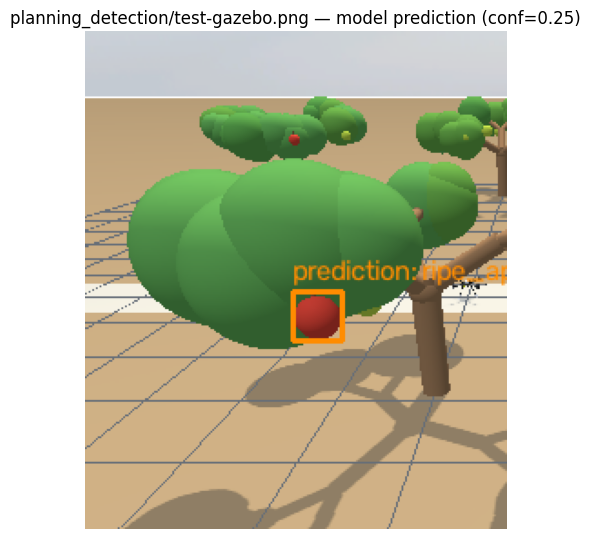

In [ ]:
gazebo_img = cv2.cvtColor(cv2.imread(str(BASE / "planning_detection/test-gazebo.png")), cv2.COLOR_BGR2RGB)
results = model.predict(gazebo_img, conf=CONF, save=False, verbose=False)
for r in results:                     # same print format as author detection.py
    for box in r.boxes:
        cls_id = int(box.cls[0])
        label = model.names[cls_id]
        conf = float(box.conf[0])
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        print(label, conf, [x1, y1, x2, y2])

gz_preds = [(int(b.cls[0]), *[round(v, 1) for v in b.xyxy[0].tolist()]) for b in results[0].boxes]
plt.figure(figsize=(7, 5.5))
plt.imshow(draw_boxes(gazebo_img, gz_preds, class_names, (255, 140, 0), "prediction"))
plt.title("planning_detection/test-gazebo.png — model prediction (conf=0.25)")
plt.axis("off"); plt.tight_layout(); plt.show()

## 9. Interpretation, limitations, and validation record

**What was validated:** on a fresh Google Colab **CPU** runtime this notebook downloaded the pinned author files, verified every byte against the GitHub tree of commit `4d42dbbf5748a1ce8afdbf3b7c9df3477a12772f`, loaded the committed fine-tuned YOLOv8n `best.pt`, and ran author-style inference (`conf=0.25`) on the 4 committed validation images and on the author's `test-gazebo.png`. Predictions were compared with the author's committed reference annotations (counts + IoU≥0.5 matches) — see the table above for the actual observed numbers.

**Interpretation / 考察（日本語）:** 本ノートブックは、著者のコミット済みチェックポイントと正解ラベルを用いた最小推論デモです。上の表に実行時の実際の観測値が表示されます。少数の画像での一致率は参考値であり、論文の性能主張の検証ではありません。

**Limitations:**
- This is a **single-example / partial demonstration**. It does not reproduce the paper's TABLE I metrics (e.g. 63.1% average ripe fruit detection rate), which were measured inside the full Gazebo + PX4 simulation pipeline with viewpoint sweeps.
- The repo has **no LICENSE**; the paper does not cite the repo (attribution rests on the exact title match in the README). Fruit species mapping (apple classes vs. the abstract's "tropical plantations") is unstated in the paper.
- Out of scope: Whisper voice commands, Gemini/Phi-3 task planning, Gazebo/PX4 SITL navigation, RRT*, and video tracking/deduplication (`tracker.py`).

**References:**
- Paper: arXiv:2610.09398v1 — https://arxiv.org/abs/2610.09398
- Author code (pinned): https://github.com/dinhtrung1308/IVG-UAV/tree/4d42dbbf5748a1ce8afdbf3b7c9df3477a12772f — specifically `planning_detection/detection.py`, `data.yaml`, `runs/detect/train-2/args.yaml`, `runs/detect/train-2/weights/best.pt`
- Ultralytics YOLOv8: https://docs.ultralytics.com/